<a href="https://colab.research.google.com/github/utsavmakavana455-ops/EcoMove-Mobility-sustainable-urban-mobility-investigation/blob/main/ecomove_analysis_executed_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EcoMove Mobility - Data Visualisation Investigation (COM7021)
Student ID: **[ADD YOUR STUDENT ID HERE]**

Structure: 1) Import  2) Inspect  3) Clean and prepare  4) Statistics  5) Visualisations  6) Save outputs.
The interactive dashboard is in a separate file (`ecomove_dashboard.py`).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [4]:
sns.set_style("whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATA_FILE = "EcoMoveMobility.xlsx"   # change the path if the file is stored elsewhere
FIG_DIR = "figures"                  # charts are saved here so they can be pasted into the report
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Import the data

In [6]:
df = pd.read_excel(DATA_FILE)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (5000, 18)


,Record_ID,Date,City,Country,Transport_Mode,Route_Type,Weather,Event_Day,Passengers,Trips,Average_Delay_Minutes,On_Time_Percentage,Ticket_Revenue_EUR,Operating_Cost_EUR,CO2_Saved_KG,Energy_Consumption_KWh,Customer_Rating,Accessibility_Complaints
0,EM-00001,45747,Paris,France,Tram,Tourist Zone,Cloudy,Yes,22946,101,3.2,85.1,58846.34,47796.73,2005.0,1446.4,4.4,26
1,EM-00002,45717,Paris,France,Tram,University Area,Cloudy,No,9417,59,1.5,90.1,24578.85,20708.01,824.3,495.1,4.7,7
2,EM-00003,45882,Rotterdam,Netherlands,Tram,Airport Connector,Clear,No,6467,38,3.4,87.9,15168.68,14129.41,693.1,405.8,4.4,7
3,EM-00004,45504,Lyon,France,Tram,University Area,Clear,Yes,5218,33,6.9,74.5,14172.20,11945.52,600.1,278.1,3.9,7
4,EM-00005,45578,Amsterdam,Netherlands,Metro,Tourist Zone,Cloudy,No,10258,19,3.6,83.2,27534.92,28846.82,1392.4,580.5,4.4,12


## 2. Initial inspection
Checking structure, data types, missing values and duplicates before changing anything.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Record_ID                 5000 non-null   object 
 1   Date                      5000 non-null   int64  
 2   City                      5000 non-null   object 
 3   Country                   5000 non-null   object 
 4   Transport_Mode            5000 non-null   object 
 5   Route_Type                5000 non-null   object 
 6   Weather                   5000 non-null   object 
 7   Event_Day                 5000 non-null   object 
 8   Passengers                5000 non-null   int64  
 9   Trips                     5000 non-null   int64  
 10  Average_Delay_Minutes     5000 non-null   float64
 11  On_Time_Percentage        5000 non-null   float64
 12  Ticket_Revenue_EUR        5000 non-null   float64
 13  Operating_Cost_EUR        5000 non-null   float64
 14  CO2_Save

In [8]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Record_IDs:", df["Record_ID"].duplicated().sum())

Missing values per column:
Record_ID                   0
Date                        0
City                        0
Country                     0
Transport_Mode              0
Route_Type                  0
Weather                     0
Event_Day                   0
Passengers                  0
Trips                       0
Average_Delay_Minutes       0
On_Time_Percentage          0
Ticket_Revenue_EUR          0
Operating_Cost_EUR          0
CO2_Saved_KG                0
Energy_Consumption_KWh      0
Customer_Rating             0
Accessibility_Complaints    0
dtype: int64

Duplicate rows: 0
Duplicate Record_IDs: 0


In [9]:
# Categorical columns: check for spelling or spacing variants
cat_cols = ["City", "Country", "Transport_Mode", "Route_Type", "Weather", "Event_Day"]
for col in cat_cols:
    print(f"\n{col} ({df[col].nunique()} values)")
    print(df[col].value_counts().to_string())


City (12 values)
City
Amsterdam    478
Vienna       434
Munich       428
Hamburg      424
Paris        422
Rome         420
Berlin       408
Barcelona    408
Rotterdam    402
Milan        400
Lyon         388
Madrid       388

Country (6 values)
Country
Germany        1260
Netherlands     880
Italy           820
France          810
Spain           796
Austria         434

Transport_Mode (6 values)
Transport_Mode
Bus              1375
Metro            1047
Tram              761
Bike Share        759
Park and Ride     585
E-Scooter         473

Route_Type (6 values)
Route_Type
Tourist Zone         904
Commuter Corridor    831
Central Route        820
Airport Connector    818
Suburban Feeder      817
University Area      810

Weather (6 values)
Weather
Clear       2071
Cloudy      1293
Rain         905
Windy        306
Heatwave     243
Snow         182

Event_Day (2 values)
Event_Day
No     4490
Yes     510


## 3. Cleaning and preparation
Each step records what was changed and why.

In [10]:
df["Date"] = pd.to_datetime(df["Date"], unit="D", origin="1899-12-30")
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())

Date range: 2024-01-01 to 2025-12-31


In [11]:
changed = 0
for col in cat_cols:
    cleaned = df[col].str.strip()
    changed += (cleaned != df[col]).sum()
    df[col] = cleaned
print("Text values changed by trimming:", changed)

Text values changed by trimming: 0


In [12]:
print("Cities with more than one country:",
      (df.groupby("City")["Country"].nunique() > 1).sum())

Cities with more than one country: 0


In [13]:
checks = {
    "On_Time_Percentage outside 0-100": ~df["On_Time_Percentage"].between(0, 100),
    "Customer_Rating outside 1-5": ~df["Customer_Rating"].between(1, 5),
    "Negative delay": df["Average_Delay_Minutes"] < 0,
    "Negative passengers/trips": (df["Passengers"] < 0) | (df["Trips"] < 0),
    "Negative revenue/cost": (df["Ticket_Revenue_EUR"] < 0) | (df["Operating_Cost_EUR"] < 0),
    "Negative complaints": df["Accessibility_Complaints"] < 0,
}
for name, mask in checks.items():
    print(f"{name}: {mask.sum()}")

On_Time_Percentage outside 0-100: 0
Customer_Rating outside 1-5: 0
Negative delay: 0
Negative passengers/trips: 0
Negative revenue/cost: 0
Negative complaints: 0


In [14]:
zero_energy = df[df["Energy_Consumption_KWh"] == 0]
zero_delay = df[df["Average_Delay_Minutes"] == 0]
print("Zero energy rows:", len(zero_energy))
print(zero_energy["Transport_Mode"].value_counts().to_string())
print("\nZero delay rows:", len(zero_delay))
print(zero_delay["Transport_Mode"].value_counts().to_string())

Zero energy rows: 759
Transport_Mode
Bike Share    759

Zero delay rows: 185
Transport_Mode
Bike Share    118
E-Scooter      63
Metro           4


In [15]:
# Large values are mostly big Metro/Bus records, so they are real demand, not errors.
num_cols = ["Passengers", "Trips", "Average_Delay_Minutes", "On_Time_Percentage",
            "Ticket_Revenue_EUR", "Operating_Cost_EUR", "CO2_Saved_KG",
            "Energy_Consumption_KWh", "Customer_Rating", "Accessibility_Complaints"]

rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, n_out, round(100 * n_out / len(df), 1)])
outlier_table = pd.DataFrame(rows, columns=["Column", "Outliers", "Percent"])
print(outlier_table.to_string(index=False))

print("\nOutlier passenger rows by mode (Passengers > upper fence):")
q1, q3 = df["Passengers"].quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
print(df.loc[df["Passengers"] > fence, "Transport_Mode"].value_counts().to_string())

                  Column  Outliers  Percent
              Passengers       525     10.5
                   Trips       955     19.1
   Average_Delay_Minutes        11      0.2
      On_Time_Percentage        10      0.2
      Ticket_Revenue_EUR       591     11.8
      Operating_Cost_EUR       780     15.6
            CO2_Saved_KG       685     13.7
  Energy_Consumption_KWh       465      9.3
         Customer_Rating        10      0.2
Accessibility_Complaints       472      9.4

Outlier passenger rows by mode (Passengers > upper fence):
Transport_Mode
Metro    525


In [16]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df["Net_Revenue_EUR"] = df["Ticket_Revenue_EUR"] - df["Operating_Cost_EUR"]
df["Complaints_per_1000"] = df["Accessibility_Complaints"] / df["Passengers"] * 1000
df["CO2_per_Passenger_KG"] = df["CO2_Saved_KG"] / df["Passengers"]
df["Energy_per_Passenger_KWh"] = df["Energy_Consumption_KWh"] / df["Passengers"]
df["Loss_Making"] = df["Net_Revenue_EUR"] < 0

df[["Date", "Month", "Net_Revenue_EUR", "Complaints_per_1000",
    "CO2_per_Passenger_KG", "Energy_per_Passenger_KWh", "Loss_Making"]].head()

,Date,Month,Net_Revenue_EUR,Complaints_per_1000,CO2_per_Passenger_KG,Energy_per_Passenger_KWh,Loss_Making
0,2025-03-31,2025-03-01,11049.61,1.133095,0.087379,0.063035,False
1,2025-03-01,2025-03-01,3870.84,0.743337,0.087533,0.052575,False
2,2025-08-13,2025-08-01,1039.27,1.082418,0.107175,0.062749,False
3,2024-07-31,2024-07-01,2226.68,1.341510,0.115006,0.053296,False
4,2024-10-13,2024-10-01,-1311.90,1.169819,0.135738,0.056590,True


**Data dictionary (key variables)**

| Variable | Meaning | Type |
|---|---|---|
| Date | Record date (converted from Excel serial) | Date |
| City / Country | Location of service | Categorical |
| Transport_Mode | Bus, Metro, Tram, Bike Share, E-Scooter, Park and Ride | Categorical |
| Route_Type | Type of route (e.g. Tourist Zone) | Categorical |
| Weather / Event_Day | Weather condition and major event flag | Categorical |
| Passengers, Trips | Demand and service volume | Numeric |
| Average_Delay_Minutes, On_Time_Percentage | Reliability | Numeric |
| Ticket_Revenue_EUR, Operating_Cost_EUR | Finance | Numeric |
| CO2_Saved_KG, Energy_Consumption_KWh | Environment | Numeric |
| Customer_Rating | Satisfaction (1-5) | Numeric |
| Accessibility_Complaints | Count of complaints | Numeric |
| Net_Revenue_EUR, Complaints_per_1000, CO2_per_Passenger_KG, Energy_per_Passenger_KWh | Derived in this notebook | Numeric |

## 4. Statistical investigation

In [17]:
# Descriptive statistics, plus skewness and mean-vs-median to show how uneven the data is
desc = df[num_cols].describe().T
desc["median"] = df[num_cols].median()
desc["skew"] = df[num_cols].skew()
print(desc[["count", "mean", "median", "std", "min", "max", "skew"]].round(2).to_string())

                           count      mean    median       std     min        max  skew
Passengers                5000.0   8181.94   4398.00  10018.72   64.00   66416.00  1.90
Trips                     5000.0    121.77     52.00    155.79   11.00    1048.00  2.13
Average_Delay_Minutes     5000.0      4.35      4.40      2.39    0.00      12.50  0.16
On_Time_Percentage        5000.0     82.06     82.00      7.93   55.00      99.00 -0.15
Ticket_Revenue_EUR        5000.0  22328.12  11190.02  28822.41   90.93  204386.05  1.95
Operating_Cost_EUR        5000.0  22422.00  11638.28  26114.32  978.37  178936.39  2.15
CO2_Saved_KG              5000.0    896.39    338.30   1261.16    8.30    8884.10  2.09
Energy_Consumption_KWh    5000.0    466.81    269.70    564.22    0.00    3856.30  1.85
Customer_Rating           5000.0      4.01      4.00      0.40    2.70       4.90 -0.24
Accessibility_Complaints  5000.0     12.53      7.00     16.97    0.00     147.00  2.59


In [18]:
# Overall KPIs
total_pax = df["Passengers"].sum()
total_rev = df["Ticket_Revenue_EUR"].sum()
total_cost = df["Operating_Cost_EUR"].sum()
kpis = {
    "Total passengers": total_pax,
    "Total ticket revenue (EUR)": total_rev,
    "Total operating cost (EUR)": total_cost,
    "Cost recovery (%)": total_rev / total_cost * 100,
    "Average delay (min)": df["Average_Delay_Minutes"].mean(),
    "Average on-time (%)": df["On_Time_Percentage"].mean(),
    "Average rating": df["Customer_Rating"].mean(),
    "Total CO2 saved (tonnes)": df["CO2_Saved_KG"].sum() / 1000,
    "Total accessibility complaints": df["Accessibility_Complaints"].sum(),
    "Complaints per 1,000 passengers": df["Accessibility_Complaints"].sum() / total_pax * 1000,
    "Loss-making records (%)": df["Loss_Making"].mean() * 100,
}
for k, v in kpis.items():
    print(f"{k}: {v:,.2f}")

Total passengers: 40,909,721.00
Total ticket revenue (EUR): 111,640,614.26
Total operating cost (EUR): 112,110,015.97
Cost recovery (%): 99.58
Average delay (min): 4.35
Average on-time (%): 82.06
Average rating: 4.01
Total CO2 saved (tonnes): 4,481.97
Total accessibility complaints: 62,661.00
Complaints per 1,000 passengers: 1.53
Loss-making records (%): 45.44


In [19]:
# Transport mode summary. Volumes are summed; delay, on-time and rating are averaged per record.
mode_summary = df.groupby("Transport_Mode").agg(
    Records=("Record_ID", "count"),
    Passengers=("Passengers", "sum"),
    Avg_Delay=("Average_Delay_Minutes", "mean"),
    Avg_OnTime=("On_Time_Percentage", "mean"),
    Avg_Rating=("Customer_Rating", "mean"),
    Revenue=("Ticket_Revenue_EUR", "sum"),
    Cost=("Operating_Cost_EUR", "sum"),
    CO2_Saved=("CO2_Saved_KG", "sum"),
    Energy=("Energy_Consumption_KWh", "sum"),
    Complaints=("Accessibility_Complaints", "sum"),
)
mode_summary["Cost_Recovery_%"] = mode_summary["Revenue"] / mode_summary["Cost"] * 100
mode_summary["Net_Revenue"] = mode_summary["Revenue"] - mode_summary["Cost"]
mode_summary["Complaints_per_1000"] = mode_summary["Complaints"] / mode_summary["Passengers"] * 1000
mode_summary["CO2_per_Passenger"] = mode_summary["CO2_Saved"] / mode_summary["Passengers"]
mode_summary["Energy_per_Passenger"] = mode_summary["Energy"] / mode_summary["Passengers"]
mode_summary["Passenger_Share_%"] = mode_summary["Passengers"] / mode_summary["Passengers"].sum() * 100
print(mode_summary.round(2).sort_values("Passengers", ascending=False).to_string())

                Records  Passengers  Avg_Delay  Avg_OnTime  Avg_Rating      Revenue         Cost  CO2_Saved     Energy  Complaints  Cost_Recovery_%  Net_Revenue  Complaints_per_1000  CO2_per_Passenger  Energy_per_Passenger  Passenger_Share_%
Transport_Mode                                                                                                                                                                                                                                   
Metro              1047    25757522       3.73       84.09        4.09  73334170.86  69029226.89  3150917.3  1439059.8       38240           106.24   4304943.97                 1.48               0.12                  0.06              62.96
Tram                761     6380878       4.79       80.63        3.94  15666167.52  13355946.79   646918.7   389196.2        9621           117.30   2310220.73                 1.51               0.10                  0.06              15.60
Bus                1375     5073

In [20]:
# City summary
city_summary = df.groupby(["City", "Country"]).agg(
    Passengers=("Passengers", "sum"),
    Avg_Delay=("Average_Delay_Minutes", "mean"),
    Avg_OnTime=("On_Time_Percentage", "mean"),
    Avg_Rating=("Customer_Rating", "mean"),
    Revenue=("Ticket_Revenue_EUR", "sum"),
    Cost=("Operating_Cost_EUR", "sum"),
).reset_index()
city_summary["Cost_Recovery_%"] = city_summary["Revenue"] / city_summary["Cost"] * 100
print(city_summary.sort_values("Passengers", ascending=False).round(2).to_string(index=False))

     City     Country  Passengers  Avg_Delay  Avg_OnTime  Avg_Rating     Revenue        Cost  Cost_Recovery_%
    Paris      France     4492481       4.36       81.96        3.99 12353471.88 12359500.35            99.95
   Berlin     Germany     4487351       4.55       81.37        3.98 12254517.96 12239974.21           100.12
   Munich     Germany     3603328       4.38       82.01        4.01  9912290.08  9741051.40           101.76
Barcelona       Spain     3526320       4.11       82.80        4.06  9642790.24  9795484.13            98.44
     Rome       Italy     3418626       4.16       82.71        4.01  9286877.93  9381339.80            98.99
   Vienna     Austria     3388470       4.32       82.39        4.01  9321041.96  9230946.16           100.98
Amsterdam Netherlands     3364412       4.44       81.70        4.00  9139564.71  9169223.29            99.68
   Madrid       Spain     3289904       4.35       82.00        4.03  8893197.14  9165684.00            97.03
    Milan 

In [21]:
# Weather, event day and route type summaries
for col in ["Weather", "Event_Day", "Route_Type"]:
    summary = df.groupby(col).agg(
        Records=("Record_ID", "count"),
        Avg_Passengers=("Passengers", "mean"),
        Avg_Delay=("Average_Delay_Minutes", "mean"),
        Avg_OnTime=("On_Time_Percentage", "mean"),
        Avg_Rating=("Customer_Rating", "mean"),
        Avg_Complaints=("Accessibility_Complaints", "mean"),
    )
    print(f"\n--- By {col} ---")
    print(summary.round(2).sort_values("Avg_Delay", ascending=False).to_string())


--- By Weather ---
          Records  Avg_Passengers  Avg_Delay  Avg_OnTime  Avg_Rating  Avg_Complaints
Weather                                                                             
Snow          182         6743.77       8.14       69.97        3.36           10.99
Rain          905         7317.58       5.40       78.70        3.70           11.44
Heatwave      243         6583.61       4.91       80.19        3.76           10.32
Windy         306         8398.88       4.86       80.42        4.02           13.47
Cloudy       1293         8219.07       3.89       83.46        4.12           12.18
Clear        2071         8818.36       3.71       84.17        4.15           13.49

--- By Event_Day ---
           Records  Avg_Passengers  Avg_Delay  Avg_OnTime  Avg_Rating  Avg_Complaints
Event_Day                                                                            
Yes            510        10057.93       5.53       78.21        3.87           15.68
No            4490  

In [22]:
# Yearly comparison (2024 v 2025)
year_summary = df.groupby("Year").agg(
    Records=("Record_ID", "count"),
    Passengers=("Passengers", "sum"),
    Avg_Delay=("Average_Delay_Minutes", "mean"),
    Avg_Rating=("Customer_Rating", "mean"),
    Revenue=("Ticket_Revenue_EUR", "sum"),
    Cost=("Operating_Cost_EUR", "sum"),
)
print(year_summary.round(2).to_string())

      Records  Passengers  Avg_Delay  Avg_Rating      Revenue         Cost
Year                                                                      
2024     2567    20974355       4.32        4.01  57242670.54  57469124.42
2025     2433    19935366       4.39        4.01  54397943.72  54640891.55


In [23]:
# Correlations: which measures move together?
corr = df[num_cols].corr()
print(corr.round(2).to_string())

                          Passengers  Trips  Average_Delay_Minutes  On_Time_Percentage  Ticket_Revenue_EUR  Operating_Cost_EUR  CO2_Saved_KG  Energy_Consumption_KWh  Customer_Rating  Accessibility_Complaints
Passengers                      1.00  -0.33                  -0.03                0.02                1.00                0.98          0.99                    0.99             0.05                      0.87
Trips                          -0.33   1.00                  -0.54                0.52               -0.33               -0.20         -0.28                   -0.36             0.40                     -0.30
Average_Delay_Minutes          -0.03  -0.54                   1.00               -0.97               -0.04               -0.11         -0.07                    0.01            -0.82                      0.01
On_Time_Percentage              0.02   0.52                  -0.97                1.00                0.03                0.11          0.07                   -0.01    

In [24]:
# Hypothesis tests (each reported with the group averages)
# 1) Event days v normal days - Welch t-test (does not assume equal variance)
event = df.loc[df["Event_Day"] == "Yes", "Average_Delay_Minutes"]
normal = df.loc[df["Event_Day"] == "No", "Average_Delay_Minutes"]
t_stat, p_val = stats.ttest_ind(event, normal, equal_var=False)
print(f"Delay on event days: {event.mean():.2f} min | normal days: {normal.mean():.2f} min")
print(f"Welch t-test: t = {t_stat:.2f}, p = {p_val:.3g}")

# 2) Delay differs across weather types - Kruskal-Wallis (non-parametric, safe for uneven groups)
groups = [g["Average_Delay_Minutes"].values for _, g in df.groupby("Weather")]
h_stat, p_kw = stats.kruskal(*groups)
print(f"\nKruskal-Wallis across weather types: H = {h_stat:.1f}, p = {p_kw:.3g}")

# 3) Delay v rating - Spearman rank correlation (robust to non-normal data)
rho, p_rho = stats.spearmanr(df["Average_Delay_Minutes"], df["Customer_Rating"])
print(f"\nSpearman delay v rating: rho = {rho:.2f}, p = {p_rho:.3g}")

# Effect sizes: how BIG the differences are, not just whether they exist
pooled_sd = np.sqrt(((len(event) - 1) * event.var() + (len(normal) - 1) * normal.var())
                    / (len(event) + len(normal) - 2))
print(f"\nCohen's d for event v normal delay: {(event.mean() - normal.mean()) / pooled_sd:.2f}")
print(f"Kruskal-Wallis effect size (epsilon-squared): {h_stat / (len(df) - 1):.3f}")

Delay on event days: 5.53 min | normal days: 4.22 min
Welch t-test: t = 11.84, p = 2.49e-29

Kruskal-Wallis across weather types: H = 677.8, p = 3.17e-144

Spearman delay v rating: rho = -0.81, p = 0

Cohen's d for event v normal delay: 0.56
Kruskal-Wallis effect size (epsilon-squared): 0.136


In [25]:
# 1) Is the fall in 2025 passengers real, or are there simply fewer records in 2025?
year_check = df.groupby("Year").agg(
    Records=("Record_ID", "count"),
    Total_Passengers=("Passengers", "sum"),
    Avg_Passengers_per_Record=("Passengers", "mean"),
)
print(year_check.round(0).to_string())
print("Change in total passengers 2024->2025 (%):",
      round((year_check.loc[2025, "Total_Passengers"] / year_check.loc[2024, "Total_Passengers"] - 1) * 100, 1))
print("Change in number of records 2024->2025 (%):",
      round((year_check.loc[2025, "Records"] / year_check.loc[2024, "Records"] - 1) * 100, 1))

# 2) Does delay lower ratings inside every mode? (guards against a mode-mix effect)
print("\nDelay v rating correlation inside each mode:")
for m, g in df.groupby("Transport_Mode"):
    print(f"  {m}: {g['Average_Delay_Minutes'].corr(g['Customer_Rating']):.2f}")

# 3) Simple regression of rating on delay
reg = stats.linregress(df["Average_Delay_Minutes"], df["Customer_Rating"])
print(f"\nRegression: rating falls {abs(reg.slope):.3f} points per extra delay minute, R-squared = {reg.rvalue**2:.3f}")

# 4) Rating gap NOT explained by delay: average residual from that line, by weather
resid = df["Customer_Rating"] - (reg.intercept + reg.slope * df["Average_Delay_Minutes"])
print("\nAverage rating residual by weather (negative = lower rating than delay alone predicts):")
print(resid.groupby(df["Weather"]).mean().round(2).sort_values().to_string())

# 5) Money and carbon per passenger, and loss-making share, by mode
unit = mode_summary[["Revenue", "Cost", "Passengers", "CO2_Saved"]].copy()
unit["Revenue_per_Pax"] = unit["Revenue"] / unit["Passengers"]
unit["Cost_per_Pax"] = unit["Cost"] / unit["Passengers"]
unit["Cost_per_Tonne_CO2"] = unit["Cost"] / (unit["CO2_Saved"] / 1000)
unit["Share_of_CO2_%"] = unit["CO2_Saved"] / unit["CO2_Saved"].sum() * 100
unit["Loss_Making_%"] = df.groupby("Transport_Mode")["Loss_Making"].mean() * 100
print("\nUnit economics and carbon by mode:")
print(unit[["Revenue_per_Pax", "Cost_per_Pax", "Loss_Making_%", "Cost_per_Tonne_CO2", "Share_of_CO2_%"]]
      .round(2).sort_values("Cost_per_Tonne_CO2").to_string())

profit_modes = unit[unit["Revenue"] > unit["Cost"]]
surplus = (profit_modes["Revenue"] - profit_modes["Cost"]).sum()
micro = unit.loc[["Bike Share", "E-Scooter"]]
micro_loss = (micro["Cost"] - micro["Revenue"]).sum()
print(f"\nCombined surplus of modes that cover their costs: EUR {surplus / 1e6:.2f}m")
print(f"Combined loss of Bike Share + E-Scooter: EUR {micro_loss / 1e6:.2f}m")
print(f"Network net revenue: EUR {(total_rev - total_cost) / 1e6:.2f}m")
print("Share of CO2 saved by Metro + Tram + Park and Ride (%):",
      round(unit.loc[["Metro", "Tram", "Park and Ride"], "Share_of_CO2_%"].sum(), 1))
print("Records behind a 'Bus in Snow' dashboard view:",
      ((df["Transport_Mode"] == "Bus") & (df["Weather"] == "Snow")).sum())

# 6) Event days: passenger uplift, cost recovery and delay uplift by mode
ev = df.groupby("Event_Day").agg(Avg_Passengers=("Passengers", "mean"),
                                 Revenue=("Ticket_Revenue_EUR", "sum"), Cost=("Operating_Cost_EUR", "sum"))
ev["Cost_Recovery_%"] = ev["Revenue"] / ev["Cost"] * 100
print("\nEvent v normal days:")
print(ev[["Avg_Passengers", "Cost_Recovery_%"]].round(1).to_string())
print("Passenger uplift on event days (%):",
      round((ev.loc["Yes", "Avg_Passengers"] / ev.loc["No", "Avg_Passengers"] - 1) * 100, 1))
ev_acc = df.groupby("Event_Day").agg(c=("Accessibility_Complaints", "sum"), p=("Passengers", "sum"),
                                     avg_c=("Accessibility_Complaints", "mean"))
print("Average complaints per record (No / Yes):", ev_acc["avg_c"].round(2).tolist())
print("Complaints per 1,000 passengers (No / Yes):", (ev_acc["c"] / ev_acc["p"] * 1000).round(2).tolist())
event_delay = df.pivot_table(index="Transport_Mode", columns="Event_Day", values="Average_Delay_Minutes")
event_delay["Extra_minutes"] = event_delay["Yes"] - event_delay["No"]
print("\nAverage delay by mode on normal (No) and event (Yes) days:")
print(event_delay.round(2).to_string())

# 7) Share of records with a delay over 8 minutes (a simple 'bad day' measure)
df["Delay_Over_8"] = df["Average_Delay_Minutes"] > 8
print("\nShare of records with delay over 8 minutes (%), by weather:")
print((df.groupby("Weather")["Delay_Over_8"].mean() * 100).round(1).sort_values().to_string())
print("By mode:")
print((df.groupby("Transport_Mode")["Delay_Over_8"].mean() * 100).round(1).sort_values().to_string())

# 8) City share of passengers
city_share = city_summary.set_index("City")["Passengers"].sort_values(ascending=False)
print("\nCity share of passengers (%):")
print((city_share / city_share.sum() * 100).round(1).to_string())
print("Country share of passengers (%):")
print((df.groupby("Country")["Passengers"].sum() / total_pax * 100).round(1).sort_values(ascending=False).to_string())

# 9) Robustness: do the conclusions change if delay, on-time and rating are weighted by passengers?
# (Each record is treated equally above; a busy record arguably deserves more weight.)
def weighted(g, col):
    return np.average(g[col], weights=g["Passengers"])

print("\nOverall unweighted v passenger-weighted:")
for col in ["Average_Delay_Minutes", "On_Time_Percentage", "Customer_Rating"]:
    print(f"  {col}: {df[col].mean():.2f} v {weighted(df, col):.2f}")

for by in ["Transport_Mode", "Weather", "Event_Day"]:
    table = pd.DataFrame({
        "Delay_unweighted": df.groupby(by)["Average_Delay_Minutes"].mean(),
        "Delay_weighted": df.groupby(by).apply(lambda g: weighted(g, "Average_Delay_Minutes")),
    }).round(2)
    print(f"\nDelay by {by}:")
    print(table.to_string())

city_weighted = df.groupby("City").apply(lambda g: weighted(g, "Average_Delay_Minutes"))
print("\nCity delay range, weighted:", round(city_weighted.min(), 2), "to", round(city_weighted.max(), 2))

# 10) The Trips variable: strong overall correlation with delay, but is it real?
print("\nTrips v delay correlation, all records:", round(df["Trips"].corr(df["Average_Delay_Minutes"]), 2))
print("Trips v delay correlation inside each mode:")
for m, g in df.groupby("Transport_Mode"):
    print(f"  {m}: {g['Trips'].corr(g['Average_Delay_Minutes']):.2f}  (median trips = {g['Trips'].median():.0f})")

      Records  Total_Passengers  Avg_Passengers_per_Record
Year                                                      
2024     2567          20974355                     8171.0
2025     2433          19935366                     8194.0
Change in total passengers 2024->2025 (%): -5.0
Change in number of records 2024->2025 (%): -5.2

Delay v rating correlation inside each mode:
  Bike Share: -0.69
  Bus: -0.74
  E-Scooter: -0.73
  Metro: -0.75
  Park and Ride: -0.76
  Tram: -0.76

Regression: rating falls 0.138 points per extra delay minute, R-squared = 0.674

Average rating residual by weather (negative = lower rating than delay alone predicts):
Weather
Heatwave   -0.17
Rain       -0.16
Snow       -0.13
Cloudy      0.05
Clear       0.06
Windy       0.08

Unit economics and carbon by mode:
                Revenue_per_Pax  Cost_per_Pax  Loss_Making_%  Cost_per_Tonne_CO2  Share_of_CO2_%
Transport_Mode                                                                                  
Tram   

/tmp/ipykernel_3854/2906465315.py:93: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Delay_weighted": df.groupby(by).apply(lambda g: weighted(g, "Average_Delay_Minutes")),
/tmp/ipykernel_3854/2906465315.py:93: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "Delay_weighted": df.groupby(by).apply(lambda g: weighted(g, "Average_Delay_Minutes")),
/tmp/ipykernel_3854/2906465315.py:93: DeprecationWarning: DataFram

## 5. Visualisations
Colour choices: one sequential palette for amounts, one categorical palette for modes.
Titles state the question being answered.

In [26]:
mode_order = mode_summary.sort_values("Passengers", ascending=False).index.tolist()
mode_colours = dict(zip(mode_order, sns.color_palette("tab10", len(mode_order))))

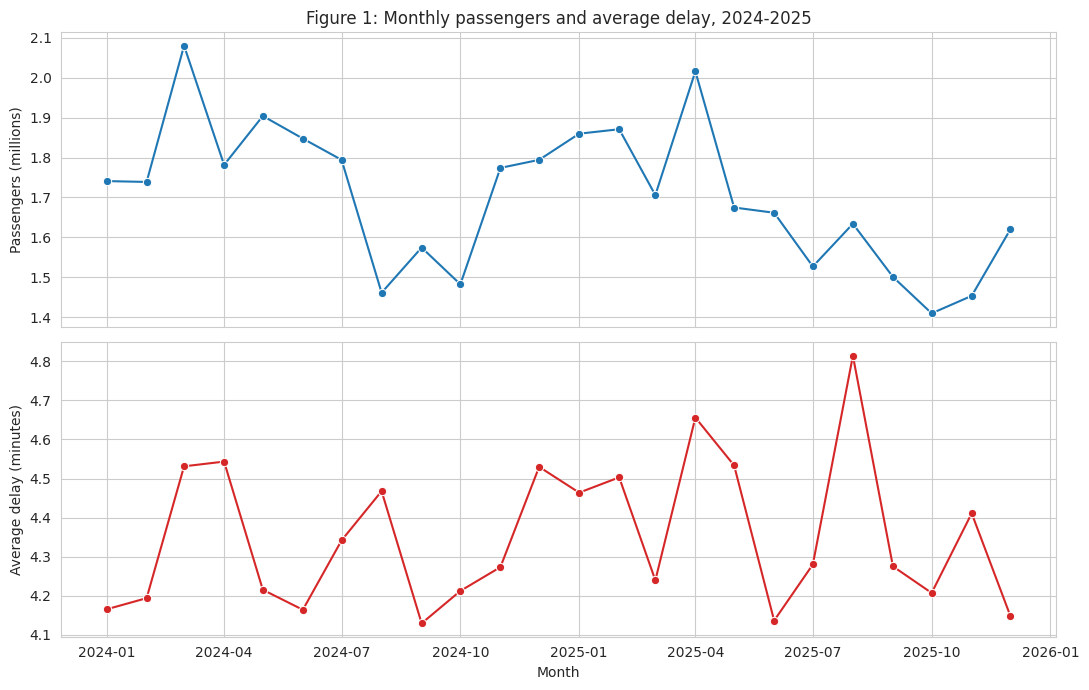

     Month  Passengers  Avg_Delay  Records
2024-01-01     1741045       4.16      197
2024-02-01     1738900       4.19      188
2024-03-01     2080100       4.53      221
2024-04-01     1781664       4.54      210
2024-05-01     1904103       4.22      219
2024-06-01     1847560       4.16      210
2024-07-01     1794190       4.34      226
2024-08-01     1461430       4.47      210
2024-09-01     1574537       4.13      227
2024-10-01     1482493       4.21      223
2024-11-01     1774105       4.27      215
2024-12-01     1794228       4.53      221
2025-01-01     1859777       4.46      210
2025-02-01     1870890       4.50      203
2025-03-01     1705973       4.24      209
2025-04-01     2015953       4.66      196
2025-05-01     1674890       4.53      191
2025-06-01     1661726       4.14      194
2025-07-01     1527158       4.28      190
2025-08-01     1634162       4.81      228
2025-09-01     1501103       4.28      188
2025-10-01     1409837       4.21      202
2025-11-01 

In [27]:
monthly = df.groupby("Month").agg(
    Passengers=("Passengers", "sum"),
    Avg_Delay=("Average_Delay_Minutes", "mean"),
    Records=("Record_ID", "count"),
).reset_index()

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
sns.lineplot(data=monthly, x="Month", y=monthly["Passengers"] / 1e6, marker="o", ax=axes[0], color="#1f77b4")
axes[0].set_ylabel("Passengers (millions)")
axes[0].set_title("Figure 1: Monthly passengers and average delay, 2024-2025")
sns.lineplot(data=monthly, x="Month", y="Avg_Delay", marker="o", ax=axes[1], color="#d62728")
axes[1].set_ylabel("Average delay (minutes)")
axes[1].set_xlabel("Month")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig01_monthly_trend.png", dpi=200)
plt.show()

print(monthly.assign(Avg_Delay=monthly["Avg_Delay"].round(2)).to_string(index=False))
print("Records per month - min:", monthly["Records"].min(), "max:", monthly["Records"].max())

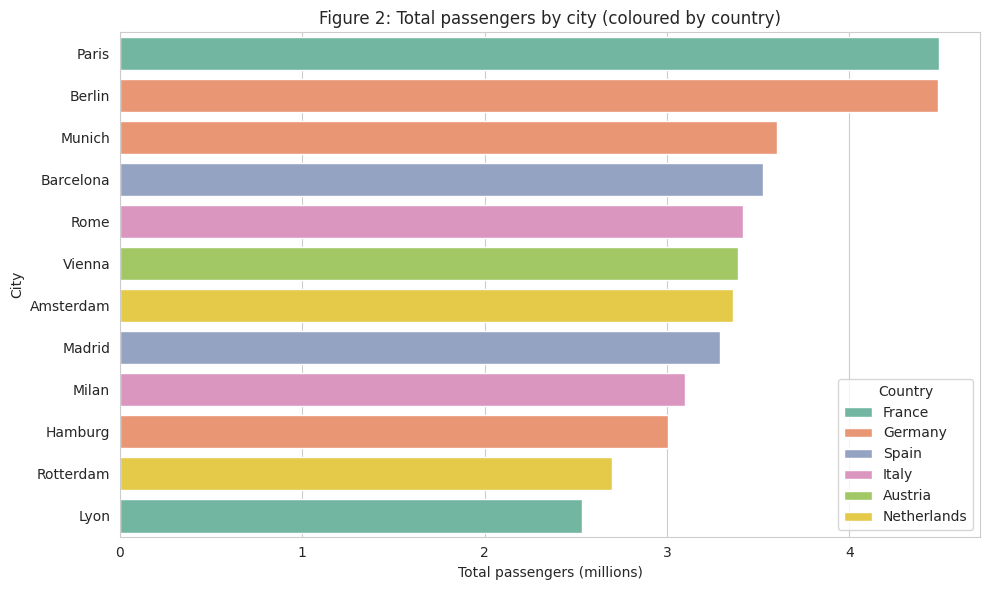

In [29]:
city_pax = city_summary.sort_values("Passengers", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=city_pax, y="City", x=city_pax["Passengers"] / 1e6,
            hue="Country", dodge=False, palette="Set2")
plt.xlabel("Total passengers (millions)")
plt.title("Figure 2: Total passengers by city (coloured by country)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig02_city_passengers.png", dpi=200)
plt.show()

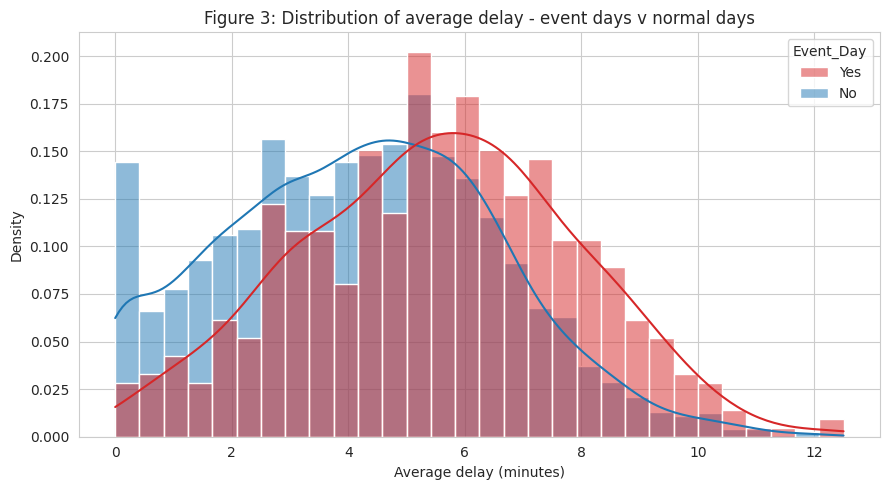

            count  mean   std  min  25%  50%   75%   max
Event_Day                                               
No         4490.0  4.22  2.35  0.0  2.5  4.2  5.90  12.3
Yes         510.0  5.53  2.37  0.0  3.8  5.6  7.18  12.5


In [28]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="Average_Delay_Minutes", hue="Event_Day", kde=True,
             stat="density", common_norm=False, bins=30, palette={"No": "#1f77b4", "Yes": "#d62728"})
plt.title("Figure 3: Distribution of average delay - event days v normal days")
plt.xlabel("Average delay (minutes)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig03_delay_distribution.png", dpi=200)
plt.show()

print(df.groupby("Event_Day")["Average_Delay_Minutes"].describe().round(2).to_string())

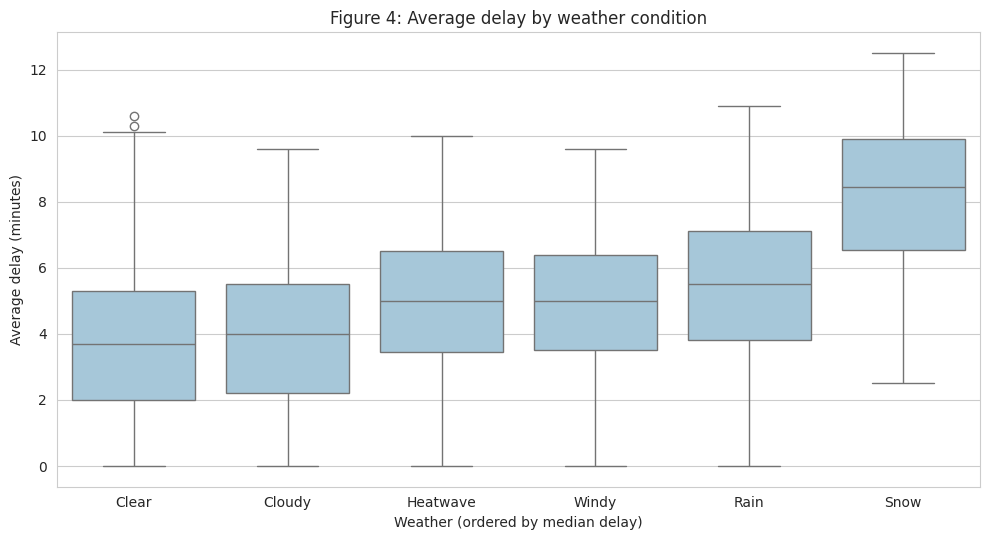

           count  mean   std  min   25%   50%  75%   max
Weather                                                 
Clear     2071.0  3.71  2.15  0.0  2.00  3.70  5.3  10.6
Cloudy    1293.0  3.89  2.15  0.0  2.20  4.00  5.5   9.6
Heatwave   243.0  4.91  2.21  0.0  3.45  5.00  6.5  10.0
Windy      306.0  4.86  2.10  0.0  3.50  5.00  6.4   9.6
Rain       905.0  5.40  2.26  0.0  3.80  5.50  7.1  10.9
Snow       182.0  8.14  2.28  2.5  6.52  8.45  9.9  12.5


In [30]:
weather_order = df.groupby("Weather")["Average_Delay_Minutes"].median().sort_values().index

plt.figure(figsize=(10, 5.5))
sns.boxplot(data=df, x="Weather", y="Average_Delay_Minutes", order=weather_order, color="#9ecae1")
plt.title("Figure 4: Average delay by weather condition")
plt.xlabel("Weather (ordered by median delay)")
plt.ylabel("Average delay (minutes)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig04_delay_by_weather.png", dpi=200)
plt.show()

print(df.groupby("Weather")["Average_Delay_Minutes"].describe().round(2).loc[weather_order].to_string())

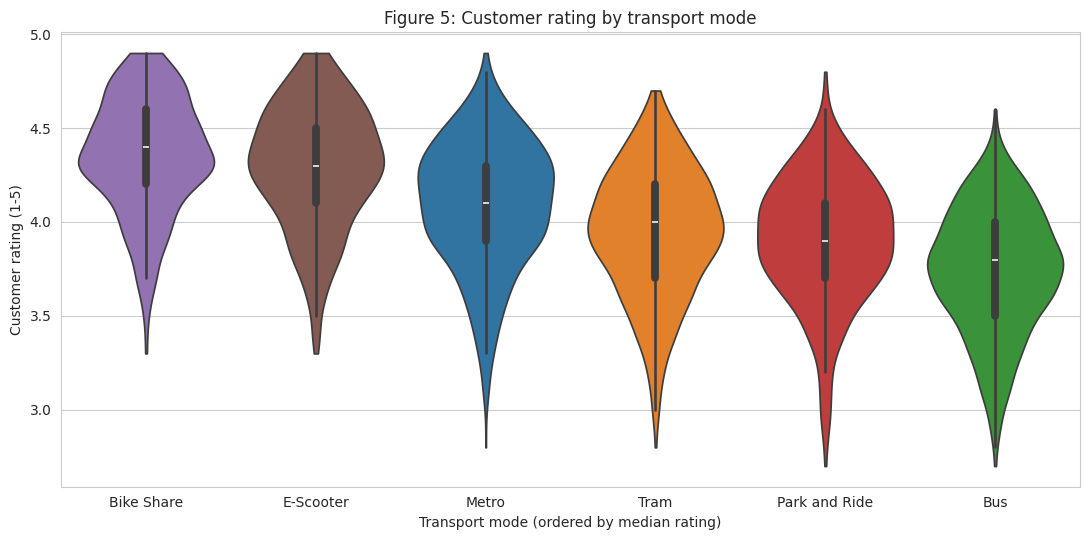

                 count  mean   std  min  25%  50%  75%  max
Transport_Mode                                             
Bike Share       759.0  4.35  0.31  3.3  4.2  4.4  4.6  4.9
E-Scooter        473.0  4.29  0.32  3.3  4.1  4.3  4.5  4.9
Metro           1047.0  4.09  0.34  2.8  3.9  4.1  4.3  4.9
Tram             761.0  3.94  0.34  2.8  3.7  4.0  4.2  4.7
Park and Ride    585.0  3.90  0.34  2.7  3.7  3.9  4.1  4.8
Bus             1375.0  3.74  0.34  2.7  3.5  3.8  4.0  4.6


In [31]:
rating_order = df.groupby("Transport_Mode")["Customer_Rating"].median().sort_values(ascending=False).index

plt.figure(figsize=(11, 5.5))
sns.violinplot(data=df, x="Transport_Mode", y="Customer_Rating", order=rating_order,
               hue="Transport_Mode", palette=mode_colours, legend=False, cut=0)
plt.title("Figure 5: Customer rating by transport mode")
plt.xlabel("Transport mode (ordered by median rating)")
plt.ylabel("Customer rating (1-5)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig05_rating_by_mode.png", dpi=200)
plt.show()

print(df.groupby("Transport_Mode")["Customer_Rating"].describe().round(2).loc[rating_order].to_string())

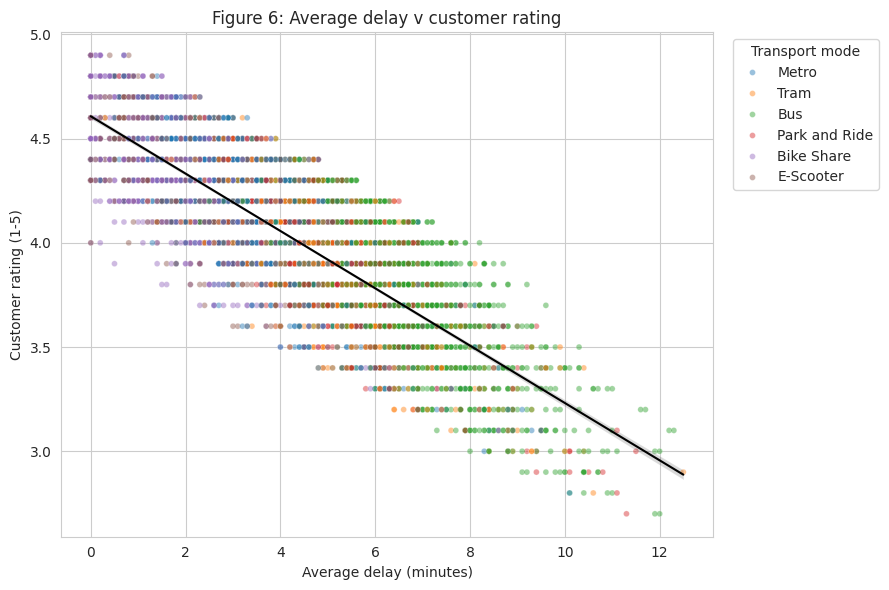

In [32]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Average_Delay_Minutes", y="Customer_Rating",
                hue="Transport_Mode", hue_order=mode_order, palette=mode_colours, alpha=0.45, s=18)
sns.regplot(data=df, x="Average_Delay_Minutes", y="Customer_Rating",
            scatter=False, color="black", line_kws={"linewidth": 1.5})
plt.title("Figure 6: Average delay v customer rating")
plt.xlabel("Average delay (minutes)")
plt.ylabel("Customer rating (1-5)")
plt.legend(title="Transport mode", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig06_delay_vs_rating.png", dpi=200)
plt.show()

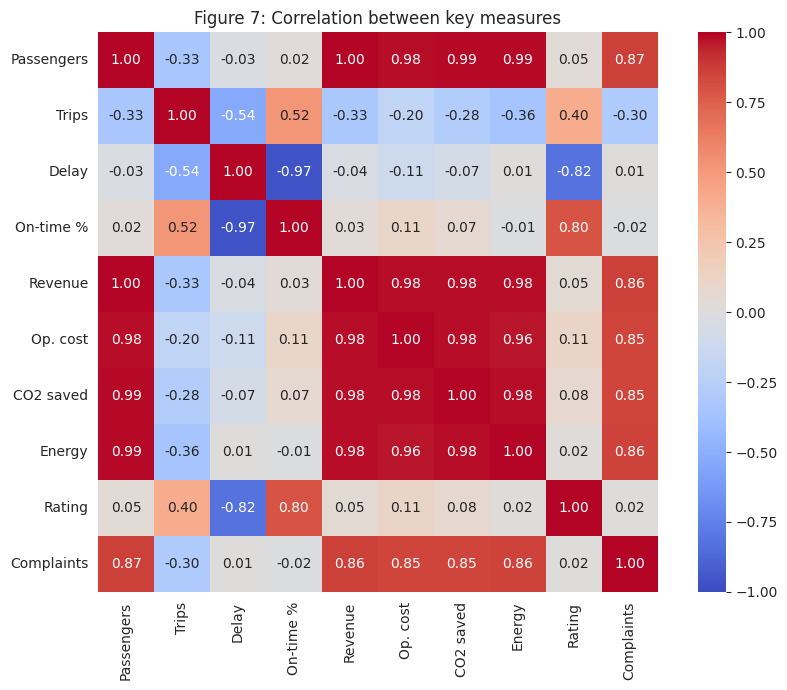

In [33]:
short = {"Average_Delay_Minutes": "Delay", "On_Time_Percentage": "On-time %", "Ticket_Revenue_EUR": "Revenue",
         "Operating_Cost_EUR": "Op. cost", "CO2_Saved_KG": "CO2 saved", "Energy_Consumption_KWh": "Energy",
         "Customer_Rating": "Rating", "Accessibility_Complaints": "Complaints"}
corr_small = df[num_cols].rename(columns=short).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_small, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Figure 7: Correlation between key measures")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig07_correlation_heatmap.png", dpi=200)
plt.show()

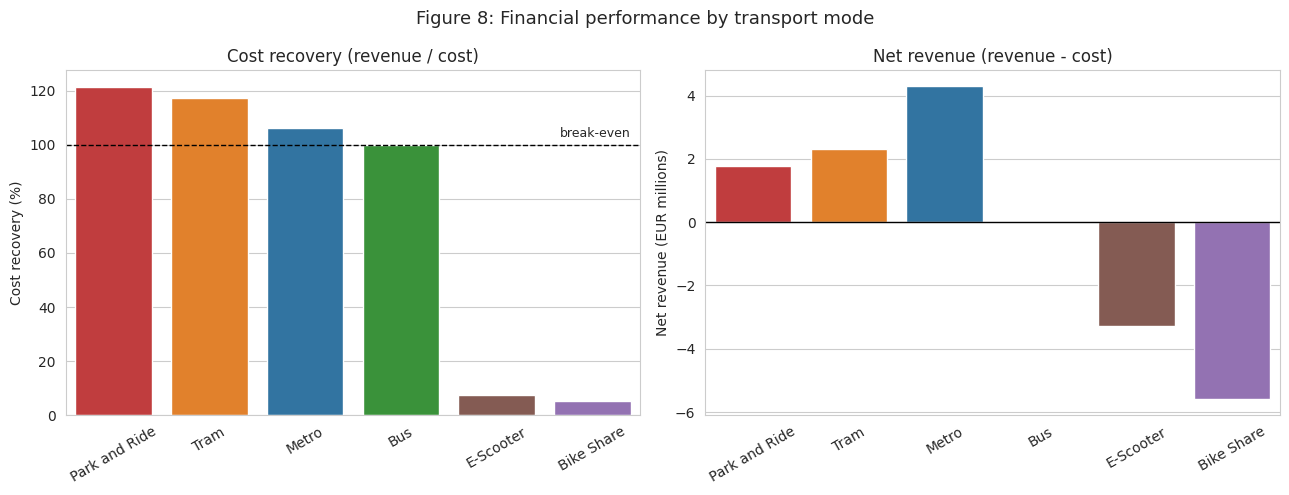

Transport_Mode    Revenue       Cost  Net_Revenue  Cost_Recovery_%
 Park and Ride 10066523.8  8283138.0    1783385.8            121.5
          Tram 15666167.5 13355946.8    2310220.7            117.3
         Metro 73334170.9 69029226.9    4304944.0            106.2
           Bus 12002118.9 11992457.4       9661.5            100.1
     E-Scooter   261278.1  3536959.6   -3275681.4              7.4
    Bike Share   310355.0  5912287.2   -5601932.2              5.2


In [34]:
fin = mode_summary.sort_values("Cost_Recovery_%", ascending=False).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=fin, x="Transport_Mode", y="Cost_Recovery_%", hue="Transport_Mode",
            palette=mode_colours, legend=False, ax=axes[0])
axes[0].axhline(100, color="black", linestyle="--", linewidth=1)
axes[0].text(5.4, 103, "break-even", ha="right", fontsize=9)
axes[0].set_title("Cost recovery (revenue / cost)")
axes[0].set_ylabel("Cost recovery (%)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=fin, x="Transport_Mode", y=fin["Net_Revenue"] / 1e6, hue="Transport_Mode",
            palette=mode_colours, legend=False, ax=axes[1])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Net revenue (revenue - cost)")
axes[1].set_ylabel("Net revenue (EUR millions)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)
fig.suptitle("Figure 8: Financial performance by transport mode", fontsize=13)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig08_finance_by_mode.png", dpi=200)
plt.show()

print(fin[["Transport_Mode", "Revenue", "Cost", "Net_Revenue", "Cost_Recovery_%"]].round(1).to_string(index=False))

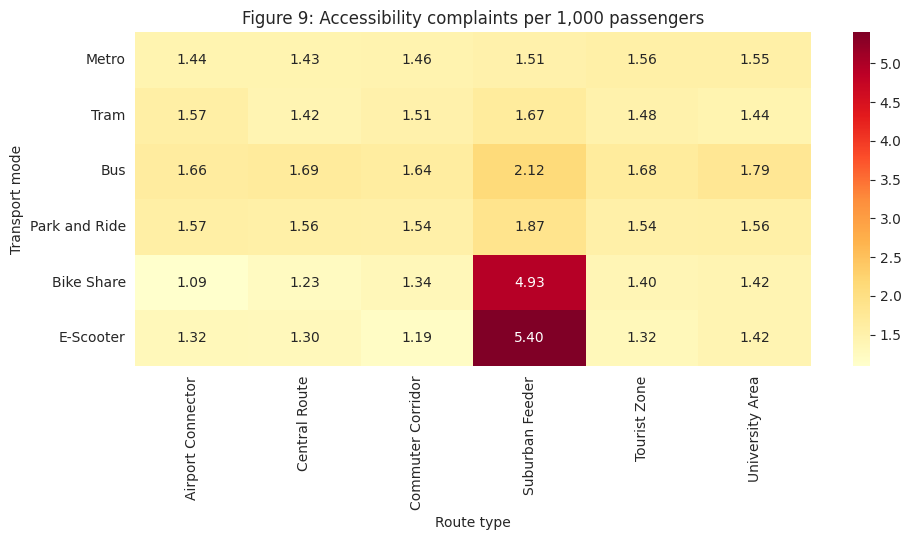

Route_Type      Airport Connector  Central Route  Commuter Corridor  Suburban Feeder  Tourist Zone  University Area
Transport_Mode                                                                                                     
Metro                        1.44           1.43               1.46             1.51          1.56             1.55
Tram                         1.57           1.42               1.51             1.67          1.48             1.44
Bus                          1.66           1.69               1.64             2.12          1.68             1.79
Park and Ride                1.57           1.56               1.54             1.87          1.54             1.56
Bike Share                   1.09           1.23               1.34             4.93          1.40             1.42
E-Scooter                    1.32           1.30               1.19             5.40          1.32             1.42
Highest cell: ('E-Scooter', 'Suburban Feeder') 5.4
Lowest cell: ('Bike S

In [35]:
# Ratio of sums (total complaints / total passengers) so large and small records are weighted fairly
access = df.groupby(["Transport_Mode", "Route_Type"]).agg(
    Complaints=("Accessibility_Complaints", "sum"), Passengers=("Passengers", "sum"))
access["per_1000"] = access["Complaints"] / access["Passengers"] * 1000
access_pivot = access["per_1000"].unstack().loc[mode_order]

plt.figure(figsize=(10, 5.5))
sns.heatmap(access_pivot, annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Figure 9: Accessibility complaints per 1,000 passengers")
plt.xlabel("Route type")
plt.ylabel("Transport mode")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig09_accessibility_heatmap.png", dpi=200)
plt.show()

print(access_pivot.round(2).to_string())
print("Highest cell:", access["per_1000"].idxmax(), round(access["per_1000"].max(), 2))
print("Lowest cell:", access["per_1000"].idxmin(), round(access["per_1000"].min(), 2))
route_access = df.groupby("Route_Type").agg(c=("Accessibility_Complaints", "sum"), p=("Passengers", "sum"))
print("\nComplaints per 1,000 passengers by route type:")
print((route_access["c"] / route_access["p"] * 1000).round(2).to_string())

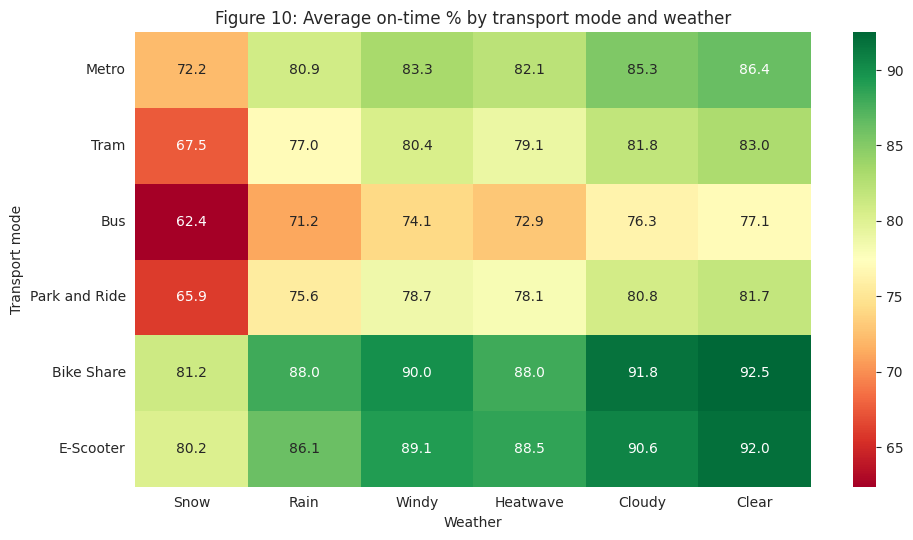

Weather         Snow  Rain  Windy  Heatwave  Cloudy  Clear
Transport_Mode                                            
Metro           72.2  80.9   83.3      82.1    85.3   86.4
Tram            67.5  77.0   80.4      79.1    81.8   83.0
Bus             62.4  71.2   74.1      72.9    76.3   77.1
Park and Ride   65.9  75.6   78.7      78.1    80.8   81.7
Bike Share      81.2  88.0   90.0      88.0    91.8   92.5
E-Scooter       80.2  86.1   89.1      88.5    90.6   92.0

On-time points lost between Clear and Snow:
Transport_Mode
Metro            14.2
Tram             15.6
Bus              14.7
Park and Ride    15.7
Bike Share       11.3
E-Scooter        11.8


In [36]:
ontime_pivot = df.pivot_table(index="Transport_Mode", columns="Weather",
                              values="On_Time_Percentage", aggfunc="mean").loc[mode_order, weather_order[::-1]]

plt.figure(figsize=(10, 5.5))
sns.heatmap(ontime_pivot, annot=True, fmt=".1f", cmap="RdYlGn")
plt.title("Figure 10: Average on-time % by transport mode and weather")
plt.xlabel("Weather")
plt.ylabel("Transport mode")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig10_ontime_mode_weather.png", dpi=200)
plt.show()

print(ontime_pivot.round(1).to_string())
print("\nOn-time points lost between Clear and Snow:")
print((ontime_pivot["Clear"] - ontime_pivot["Snow"]).round(1).to_string())

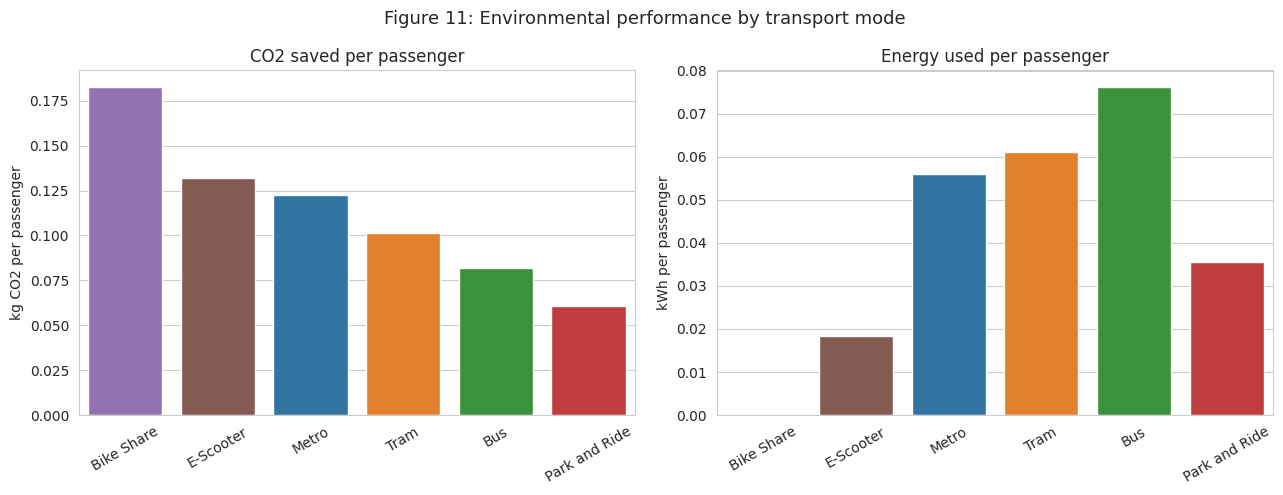

Transport_Mode  CO2_Saved  CO2_per_Passenger  Energy_per_Passenger
    Bike Share    49132.7              0.183                 0.000
     E-Scooter    21651.3              0.132                 0.018
         Metro  3150917.3              0.122                 0.056
          Tram   646918.7              0.101                 0.061
           Bus   414163.1              0.082                 0.076
 Park and Ride   199191.2              0.061                 0.036


In [37]:
env = mode_summary.sort_values("CO2_per_Passenger", ascending=False).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=env, x="Transport_Mode", y="CO2_per_Passenger", hue="Transport_Mode",
            palette=mode_colours, legend=False, ax=axes[0])
axes[0].set_title("CO2 saved per passenger")
axes[0].set_ylabel("kg CO2 per passenger")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=env, x="Transport_Mode", y="Energy_per_Passenger", hue="Transport_Mode",
            palette=mode_colours, legend=False, ax=axes[1])
axes[1].set_title("Energy used per passenger")
axes[1].set_ylabel("kWh per passenger")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)
fig.suptitle("Figure 11: Environmental performance by transport mode", fontsize=13)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig11_environment_by_mode.png", dpi=200)
plt.show()

print(env[["Transport_Mode", "CO2_Saved", "CO2_per_Passenger", "Energy_per_Passenger"]].round(3).to_string(index=False))

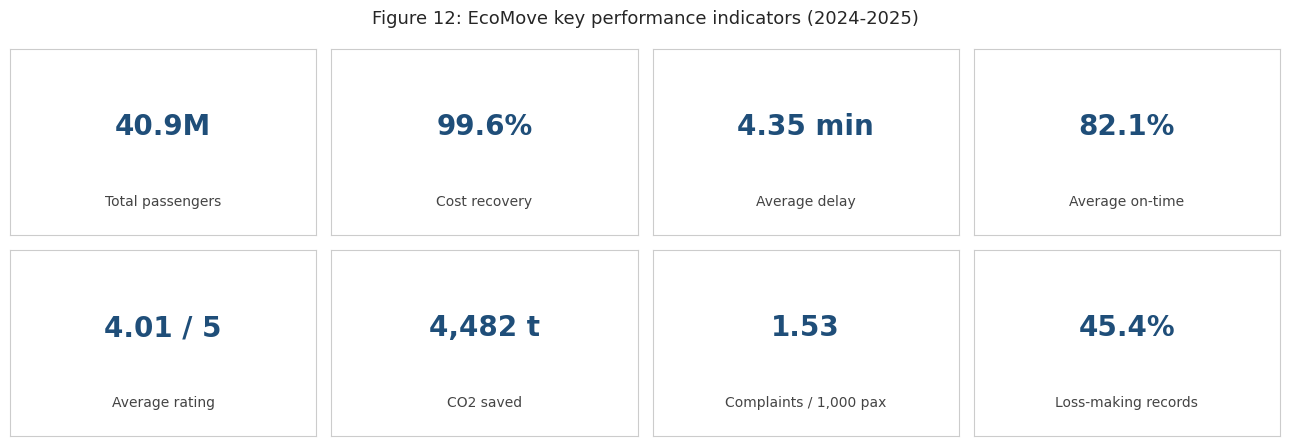

In [38]:
cards = [
    ("Total passengers", f"{kpis['Total passengers']/1e6:.1f}M"),
    ("Cost recovery", f"{kpis['Cost recovery (%)']:.1f}%"),
    ("Average delay", f"{kpis['Average delay (min)']:.2f} min"),
    ("Average on-time", f"{kpis['Average on-time (%)']:.1f}%"),
    ("Average rating", f"{kpis['Average rating']:.2f} / 5"),
    ("CO2 saved", f"{kpis['Total CO2 saved (tonnes)']:,.0f} t"),
    ("Complaints / 1,000 pax", f"{kpis['Complaints per 1,000 passengers']:.2f}"),
    ("Loss-making records", f"{kpis['Loss-making records (%)']:.1f}%"),
]
fig, axes = plt.subplots(2, 4, figsize=(13, 4.5))
for ax, (label, value) in zip(axes.flat, cards):
    ax.text(0.5, 0.58, value, ha="center", va="center", fontsize=20, fontweight="bold", color="#1f4e79")
    ax.text(0.5, 0.18, label, ha="center", va="center", fontsize=10, color="#444444")
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor("#cccccc")
fig.suptitle("Figure 12: EcoMove key performance indicators (2024-2025)", fontsize=13)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig12_kpi_cards.png", dpi=200)
plt.show()

## 6. Save the cleaned data and summary tables

In [39]:
df.to_csv("EcoMove_cleaned.csv", index=False)
mode_summary.round(3).to_csv("mode_summary.csv")
city_summary.round(3).to_csv("city_summary.csv", index=False)
print("Saved cleaned data and summary tables.")

Saved cleaned data and summary tables.
